# 03. Đánh giá Mô hình & Phân tích Sai lệch (Model Evaluation & Error Analysis)

**Thành viên phụ trách:** Thành viên 3 - Model Evaluation & Performance Analysis

**Mục tiêu:**
1. Nạp file dự đoán chuẩn hóa `reports/predictions.csv` (`load_predictions`).
2. Tính toán các chỉ số phân loại tổng thể: Precision, Recall, F1, PR-AUC, ROC-AUC (`compute_classification_metrics`, `evaluate_all_models`).
3. Đánh giá độ chính xác Top-K theo từng mùa giải (`compute_topk_accuracy_per_season`), mô phỏng việc lựa chọn đúng $k = \sum y_{true}$ suất All-Star thực tế của mùa giải đó.
4. Phân tích các trường hợp lỗi (Error Cases) (`get_error_cases`):
   - **False Positives (FP):** Cầu thủ có xác suất cao nhưng không được chọn (overhyped hoặc bị snub).
   - **False Negatives (FN):** Cầu thủ All-Star thực tế nhưng bị mô hình bỏ sót.
5. Trực quan hóa so sánh hiệu năng các mô hình và lưu biểu đồ vào `figures/evaluation/`.

In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().resolve().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", font="Segoe UI")

from src.evaluate import (
    load_predictions,
    compute_classification_metrics,
    compute_topk_accuracy_per_season,
    get_error_cases,
    evaluate_all_models
)

print("Imports thành công từ src.evaluate!")

Imports thành công từ src.evaluate!


## Bước 1: Nạp file dự đoán `reports/predictions.csv` (`load_predictions`)

In [2]:
predictions_path = ROOT_DIR / "reports" / "predictions.csv"
pred_df = load_predictions(predictions_path)

print(f"Đã nạp {len(pred_df):,} dòng kết quả dự đoán.")
print(f"Danh sách các mô hình: {pred_df['model'].unique().tolist()}")
print(f"Danh sách các splits:  {pred_df['split'].unique().tolist()}")
pred_df.head()

Đã nạp 16,276 dòng kết quả dự đoán.
Danh sách các mô hình: ['Dummy', 'LogisticRegression', 'RandomForest', 'HistGradientBoosting']
Danh sách các splits:  ['val', 'test']


,player,season,split,model,y_true,y_proba
0,Álex Abrines,2017,val,Dummy,0,0.079491
1,Álex Abrines,2018,val,Dummy,0,0.079491
2,Álex Abrines,2019,val,Dummy,0,0.079491
3,Quincy Acy,2017,val,Dummy,0,0.079491
4,Quincy Acy,2018,val,Dummy,0,0.079491


## Bước 2: Bảng xếp hạng hiệu năng mô hình (`evaluate_all_models`)
So sánh Precision, Recall, F1, PR-AUC, ROC-AUC và Top-K Accuracy trung bình trên tập Validation ($2017 - 2019$) và Test ($2020 - 2026$):

In [3]:
print("=== BẢNG XẾP HẠNG TRÊN TẬP VALIDATION (2017 - 2019) ===")
leaderboard_val = evaluate_all_models(pred_df, threshold=0.5, split="val")
display(leaderboard_val) if "display" in globals() else print(leaderboard_val)

print("\n=== BẢNG XẾP HẠNG TRÊN TẬP TEST (2020 - 2026) ===")
leaderboard_test = evaluate_all_models(pred_df, threshold=0.5, split="test")
display(leaderboard_test) if "display" in globals() else print(leaderboard_test)

=== BẢNG XẾP HẠNG TRÊN TẬP VALIDATION (2017 - 2019) ===
                  model  precision  recall        f1    pr_auc   roc_auc  \
0          RandomForest   0.815385  0.6625  0.731034  0.841250  0.984660   
1  HistGradientBoosting   0.753247  0.7250  0.738854  0.863854  0.985558   
2    LogisticRegression   0.574627  0.9625  0.719626  0.862901  0.985558   
3                 Dummy   0.000000  0.0000  0.000000  0.067397  0.500000   

   mean_topk_acc  
0       0.761711  
1       0.760723  
2       0.749259  
3       0.111323  

=== BẢNG XẾP HẠNG TRÊN TẬP TEST (2020 - 2026) ===
                  model  precision    recall        f1    pr_auc   roc_auc  \
0    LogisticRegression   0.478947  0.978495  0.643110  0.871144  0.989967   
1  HistGradientBoosting   0.733990  0.801075  0.766067  0.853164  0.986824   
2          RandomForest   0.784314  0.645161  0.707965  0.825454  0.983749   
3                 Dummy   0.000000  0.000000  0.000000  0.064539  0.500000   

   mean_topk_acc  
0      

## Bước 3: Đánh giá độ chính xác Top-K theo từng mùa giải (`compute_topk_accuracy_per_season`)
Với mỗi mùa giải, lấy $k = \sum y_{true}$ (số lượng All-Star thực tế được chọn, thường khoảng 24–28 cầu thủ), chọn ra $k$ cầu thủ có xác suất `y_proba` cao nhất và tính tỷ lệ trùng khớp (Hit Rate).

In [4]:
topk_df = compute_topk_accuracy_per_season(pred_df[pred_df["split"] == "val"])
print("Độ chính xác Top-K từng mùa giải trên tập Validation:")
display(topk_df) if "display" in globals() else print(topk_df)

Độ chính xác Top-K từng mùa giải trên tập Validation:


                   model  season   k  hits  topk_accuracy
0                  Dummy    2017  25     2       0.080000
1                  Dummy    2018  28     4       0.142857
2                  Dummy    2019  27     3       0.111111
3   HistGradientBoosting    2017  25    18       0.720000
4   HistGradientBoosting    2018  28    23       0.821429
5   HistGradientBoosting    2019  27    20       0.740741
6     LogisticRegression    2017  25    18       0.720000
7     LogisticRegression    2018  28    21       0.750000
8     LogisticRegression    2019  27    21       0.777778
9           RandomForest    2017  25    19       0.760000
10          RandomForest    2018  28    23       0.821429
11          RandomForest    2019  27    19       0.703704


## Bước 4: Phân tích các trường hợp sai lệch (Error Cases) (`get_error_cases`)
- **False Positives (FP):** Cầu thủ có `y_proba >= 0.5` nhưng không phải All-Star thực tế.
- **False Negatives (FN):** Cầu thủ All-Star thực tế nhưng mô hình dự đoán `y_proba < 0.5`.

In [5]:
# Phân tích lỗi cho mô hình RandomForest trên tập Validation
best_model_name = "RandomForest"
target_preds = pred_df[(pred_df["model"] == best_model_name) & (pred_df["split"] == "val")]

errors = get_error_cases(target_preds, threshold=0.5)
fp_df = errors["false_positives"]
fn_df = errors["false_negatives"]

print(f"=== PHÂN TÍCH LỖI MÔ HÌNH: {best_model_name} (TẬP VALIDATION) ===")
print(f"Số lượng False Positives (Dự đoán All-Star nhưng trượt): {len(fp_df)}")
print(f"Số lượng False Negatives (All-Star thực tế bị bỏ sót):    {len(fn_df)}")

print("\nTop 5 False Positives:")
print(fp_df[["player", "season", "y_true", "y_proba"]].head(5))

print("\nTop 5 False Negatives:")
print(fn_df[["player", "season", "y_true", "y_proba"]].head(5))

=== PHÂN TÍCH LỖI MÔ HÌNH: RandomForest (TẬP VALIDATION) ===
Số lượng False Positives (Dự đoán All-Star nhưng trượt): 12
Số lượng False Negatives (All-Star thực tế bị bỏ sót):    27

Top 5 False Positives:
               player  season  y_true  y_proba
0      Damian Lillard    2017       0     0.95
1  Karl-Anthony Towns    2017       0     0.94
2          Chris Paul    2018       0     0.90
3          Chris Paul    2017       0     0.86
4       Blake Griffin    2017       0     0.85

Top 5 False Negatives:
           player  season  y_true  y_proba
0   Dirk Nowitzki    2019       1     0.02
1    Goran Dragić    2018       1     0.04
2  DeAndre Jordan    2017       1     0.04
3  Draymond Green    2018       1     0.04
4     Dwyane Wade    2019       1     0.06


## Bước 5: Trực quan hóa và lưu biểu đồ vào `figures/evaluation/`

Đã lưu biểu đồ: C:\Users\Administrator\.gemini\antigravity\scratch\nba-allstar-prediction\figures\evaluation\models_topk_accuracy.png


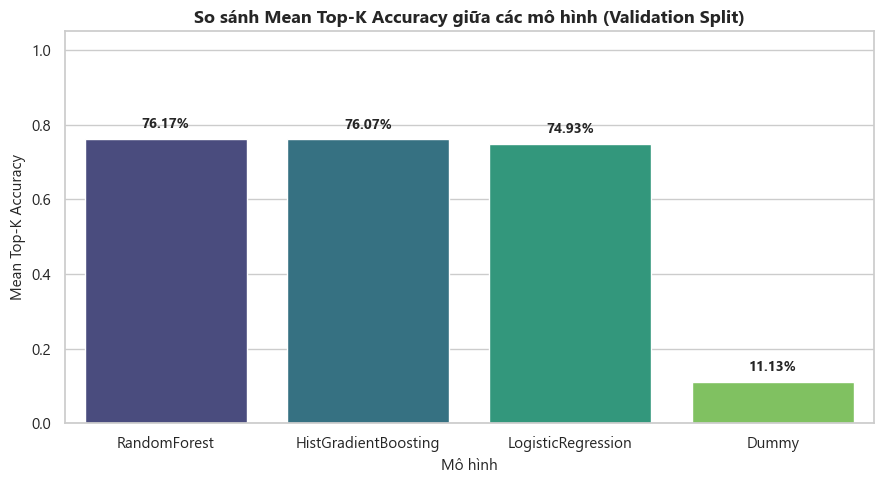

In [6]:
figures_eval_dir = ROOT_DIR / "figures" / "evaluation"
figures_eval_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=leaderboard_val, x="model", y="mean_topk_acc", hue="model", palette="viridis", legend=False)
plt.title("So sánh Mean Top-K Accuracy giữa các mô hình (Validation Split)", fontsize=13, fontweight='bold')
plt.xlabel("Mô hình", fontsize=11)
plt.ylabel("Mean Top-K Accuracy", fontsize=11)
plt.ylim(0, 1.05)

for p in ax.patches:
    h = p.get_height()
    if not np.isnan(h):
        ax.annotate(f"{h:.2%}", (p.get_x() + p.get_width() / 2., h + 0.02),
                    ha="center", va="bottom", fontweight="bold", fontsize=10)

plt.tight_layout()
chart_path = figures_eval_dir / "models_topk_accuracy.png"
plt.savefig(chart_path, dpi=300)
print(f"Đã lưu biểu đồ: {chart_path}")
plt.show()